## 1. Setup and Data Loading

This step loads the libraries and the raw 2019 NYC Airbnb listings so every later step starts from the same original data.

In [1]:
import sys; print(sys.executable)

/Users/mkml/Documents/work/Udacity/ai-programming-foundations-project/.venv/bin/python


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("AB_NYC_2019.csv")
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## 2. Initial Data Inspection

Before changing anything, this step checks the data's shape, types, missing values and suspicious values such as $0 prices, so the cleaning decisions are based on evidence.

In [4]:
missing_rpm = df["reviews_per_month"].isna()
print(missing_rpm.sum(), "missing reviews_per_month")
print((df.loc[missing_rpm, "number_of_reviews"] == 0).all(), "-> all have zero reviews?")

10052 missing reviews_per_month
True -> all have zero reviews?


In [5]:
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print(df.describe().T)
print((df["price"] == 0).sum(), "listings with price 0")
print((df["availability_365"] == 0).sum(), "listings with 0 availability")

(48895, 16)
id                                  int64
name                                  str
host_id                             int64
host_name                             str
neighbourhood_group                   str
neighbourhood                         str
latitude                          float64
longitude                         float64
room_type                             str
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                           str
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude             

## 3. Data Cleaning

This step handles missing values and removes invalid or extreme prices and minimum-night requirements that would otherwise distort the summaries and charts.

In [7]:
def handle_missing_values(df):
    """
    Handle missing values and drop columns not needed for analysis.

    - Drops 'name' (free text, not analyzed) and 'host_name'
      (personal data, not needed for the analysis).
    - Fills missing 'reviews_per_month' with 0: these rows all have
      number_of_reviews == 0, so the value is structurally missing.
    - Converts 'last_review' to datetime; never-reviewed listings stay NaT.

    Returns a new DataFrame; the input is not modified.
    """
    cleaned = df.drop(columns=["name", "host_name"]).copy()
    cleaned["reviews_per_month"] = cleaned["reviews_per_month"].fillna(0)
    cleaned["last_review"] = pd.to_datetime(cleaned["last_review"])
    return cleaned

In [8]:
df[["price", "minimum_nights"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99])

,price,minimum_nights
count,48895.000000,48895.000000
mean,152.720687,7.029962
std,240.154170,20.510550
min,0.000000,1.000000
50%,106.000000,3.000000
90%,269.000000,28.000000
95%,355.000000,30.000000
99%,799.000000,45.000000
max,10000.000000,1250.000000


In [9]:
def remove_invalid_and_extreme_values(df, price_quantile=0.99, max_min_nights=365):
    """
    Remove rows with invalid or extreme price and minimum_nights values.

    - Removes listings with price == 0 (invalid nightly price).
    - Removes listings priced above the given quantile (default 99th
      percentile), since the price distribution is strongly right-skewed.
    - Removes listings with minimum_nights above max_min_nights
      (default 365), which fall outside short-term rental use.

    Prints how many rows were removed and returns a new DataFrame.
    """
    cleaned = df[df["price"] > 0].copy()
    price_cutoff = cleaned["price"].quantile(price_quantile)
    cleaned = cleaned[
        (cleaned["price"] <= price_cutoff)
        & (cleaned["minimum_nights"] <= max_min_nights)
    ]
    print(f"Price cutoff ({price_quantile:.0%} quantile): ${price_cutoff:.0f}")
    print(f"Rows removed: {len(df) - len(cleaned)} of {len(df)}")
    return cleaned

In [10]:
df_clean = remove_invalid_and_extreme_values(handle_missing_values(df))
print(df_clean.shape)
print(df_clean.isna().sum())

Price cutoff (99% quantile): $799
Rows removed: 499 of 48895
(48396, 14)
id                                   0
host_id                              0
neighbourhood_group                  0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                       9819
reviews_per_month                    0
calculated_host_listings_count       0
availability_365                     0
dtype: int64


## 4. Bias Check: Effect of Cleaning on Borough Representation

Because removing rows can quietly change who is represented, this step compares each borough's share of listings before and after cleaning.

In [11]:
before = df[df["price"] > 0]["neighbourhood_group"].value_counts(normalize=True)
after = df_clean["neighbourhood_group"].value_counts(normalize=True)
print(pd.DataFrame({"before": before, "after": after}).round(4))

                     before   after
neighbourhood_group                
Manhattan            0.4431  0.4402
Brooklyn             0.4111  0.4130
Queens               0.1159  0.1167
Bronx                0.0223  0.0225
Staten Island        0.0076  0.0076


In [12]:
removed = df[(df["price"] > 0) & ~df["id"].isin(df_clean["id"])]
print(removed["neighbourhood_group"].value_counts(normalize=True).round(3))

neighbourhood_group
Manhattan        0.725
Brooklyn         0.223
Queens           0.037
Staten Island    0.008
Bronx            0.006
Name: proportion, dtype: float64


## 5. Exploratory Data Analysis

This step summarizes price by borough and room type and checks how the numeric columns correlate, to find the patterns worth plotting.

In [13]:
def summarize_by_group(df, group_cols, value_col="price"):
    """
    Summarize a numeric column for each group.

    Returns count, median, mean, and standard deviation of value_col
    for each combination of group_cols, sorted by median (descending).
    Median is reported alongside mean because price is right-skewed.
    """
    return (
        df.groupby(group_cols)[value_col]
        .agg(["count", "median", "mean", "std"])
        .round(1)
        .sort_values("median", ascending=False)
    )

In [14]:
summarize_by_group(df_clean, "neighbourhood_group")
summarize_by_group(df_clean, "room_type")
summarize_by_group(df_clean, ["neighbourhood_group", "room_type"])


count  median   mean    std
neighbourhood_group room_type                                   
Manhattan           Entire home/apt  12900   190.0  217.0  117.5
Brooklyn            Entire home/apt   9478   145.0  165.4   93.7
Queens              Entire home/apt   2085   120.0  140.8   79.5
Bronx               Entire home/apt    378   100.0  125.2   83.8
Staten Island       Entire home/apt    172   100.0  131.1   90.8
Manhattan           Private room      7930    90.0  106.5   75.3
                    Shared room        476    69.0   84.0   68.6
Brooklyn            Private room     10097    65.0   72.1   43.1
Queens              Private room      3368    60.0   67.8   42.8
Bronx               Private room       650    53.5   63.1   48.4
Staten Island       Private room       188    50.0   62.3   36.1
Bronx               Shared room         59    40.0   47.3   30.6
Queens              Shared room        195    37.0   49.3   46.9
Brooklyn            Shared room        411    36.0   50.8   53.5
Staten Island       Shared room          9    30.0   57.4   45.1

In [15]:
num_cols = ["price", "minimum_nights", "number_of_reviews",
            "reviews_per_month", "calculated_host_listings_count", "availability_365"]
df_clean[num_cols].corr().round(2)

,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
price,1.00,0.03,-0.06,-0.05,0.15,0.11
minimum_nights,0.03,1.00,-0.10,-0.15,0.17,0.17
number_of_reviews,-0.06,-0.10,1.00,0.59,-0.07,0.17
reviews_per_month,-0.05,-0.15,0.59,1.00,-0.05,0.17
calculated_host_listings_count,0.15,0.17,-0.07,-0.05,1.00,0.23
availability_365,0.11,0.17,0.17,0.17,0.23,1.00


## 6. Visualizations

These figures show the main patterns from the analysis visually and save each one to the `figures/` folder for the report.

In [16]:
import os
os.makedirs("figures", exist_ok=True)

### Figure 1: nightly price distribution

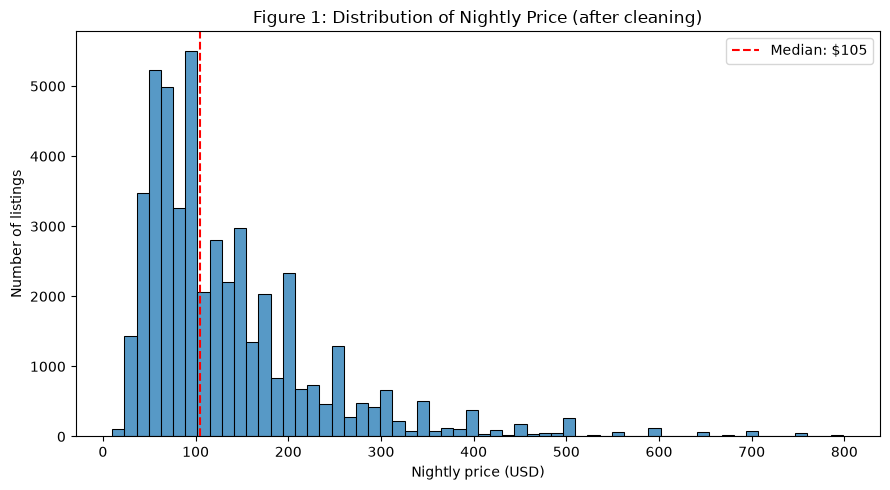

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df_clean["price"], bins=60, ax=ax)
ax.axvline(df_clean["price"].median(), color="red", linestyle="--",
           label=f"Median: ${df_clean['price'].median():.0f}")
ax.set_title("Figure 1: Distribution of Nightly Price (after cleaning)")
ax.set_xlabel("Nightly price (USD)")
ax.set_ylabel("Number of listings")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig1_price_distribution.png", dpi=150)
plt.show()

### Figure 2: price by borough and room type

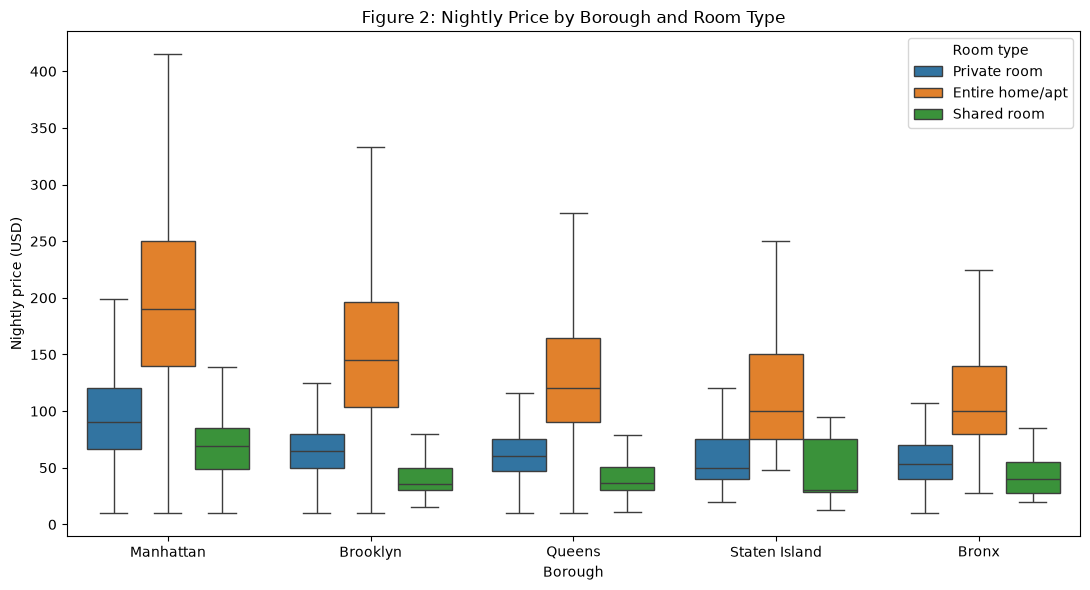

In [18]:
borough_order = (df_clean.groupby("neighbourhood_group")["price"]
                 .median().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=df_clean, x="neighbourhood_group", y="price",
            hue="room_type", order=borough_order, showfliers=False, ax=ax)
ax.set_title("Figure 2: Nightly Price by Borough and Room Type")
ax.set_xlabel("Borough")
ax.set_ylabel("Nightly price (USD)")
ax.legend(title="Room type")
plt.tight_layout()
plt.savefig("figures/fig2_price_by_borough_room.png", dpi=150)
plt.show()

### Figure 3: minimum nights

Many listings appear to require a minimum stay of about a month. This chart counts listings at each minimum-night value up to 60, on a log scale so that small counts stay visible, to see whether the 28–30 night group really stands out from the values around it.

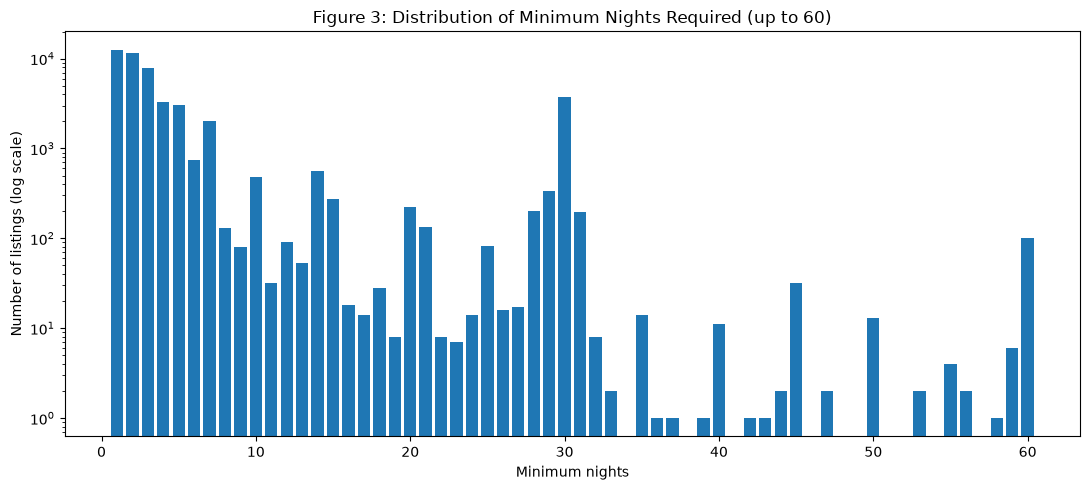

In [19]:
fig, ax = plt.subplots(figsize=(11, 5))
counts = df_clean["minimum_nights"].value_counts().sort_index()
counts = counts[counts.index <= 60]
ax.bar(counts.index, counts.values)
ax.set_yscale("log")
ax.set_title("Figure 3: Distribution of Minimum Nights Required (up to 60)")
ax.set_xlabel("Minimum nights")
ax.set_ylabel("Number of listings (log scale)")
plt.tight_layout()
plt.savefig("figures/fig3_minimum_nights.png", dpi=150)
plt.show()

## 7. Summary and Interpretation

This section brings together what the analysis found and what it means, including the limits of the data and the cleaning choices.